# MERRA-2 AOD vs AERONET-AOD @ Nghia Do — NE-monsoon dry season

**Question:** Does MERRA-2 (TOTEXTTAU, total aerosol extinction AOT @ 550 nm)
reproduce AERONET-observed AOD at Nghia Do (urban Hanoi) during the Nov-Mar
dry season?

Companion to the CAMS check — both are candidate priors. The Stage B note in
memory says Stage B uses CAMS only, but if MERRA-2 happens to be a better
matcher during haze, that's a meaningful design signal.

Comparisons are raw — no bias correction, no smoothing.


In [1]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

# Nghia Do — AERONET site in urban Hanoi
LAT, LON = 21.048, 105.800

# NE-monsoon dry season for northern Vietnam
DRY_MONTHS = [11, 12, 1, 2, 3]

# Window covered by MERRA-2 download + AERONET overlap (~2 dry seasons)
DATE_START = "2022-09-01"
DATE_END   = "2026-04-30"

AERONET_CSV = "/home/slow_data/Air_Quality/AERONET/process/aod_550/10/NGHIA_DO.csv"
MERRA2_ROOT = "/home/slow_data/Air_Quality/MERRA2/M2T1NXAER"


In [2]:
def load_aeronet(csv_path):
    """AERONET file is UTC+7 (Hanoi local, timezone-naive) — convert to UTC."""
    df = pd.read_csv(csv_path, parse_dates=["datetime"])
    df["time_utc"] = df["datetime"] - pd.Timedelta(hours=7)
    return df[["time_utc", "aod_550"]].sort_values("time_utc").reset_index(drop=True)

aeronet = load_aeronet(AERONET_CSV)
aeronet = aeronet[(aeronet.time_utc >= DATE_START) & (aeronet.time_utc <= DATE_END)]
aeronet_dry = aeronet[aeronet.time_utc.dt.month.isin(DRY_MONTHS)].reset_index(drop=True)
print(f"AERONET rows in dry season: {len(aeronet_dry):,}")
aeronet_dry.head()


AERONET rows in dry season: 5,889


,time_utc,aod_550
0,2022-11-01 01:32:54,0.203273
1,2022-11-01 01:42:55,0.195520
2,2022-11-01 02:16:11,0.216857
3,2022-11-01 03:00:58,0.224244
4,2022-11-01 03:06:11,0.243783


In [3]:
def load_merra2_at_point(root, lat, lon, start, end, var="TOTEXTTAU"):
    """
    MERRA-2 is one .nc4 per day. We open each, slice the nearest cell, and
    concat — far cheaper than open_mfdataset over ~500 daily files.
    Timestamps in the file are centred on HH:30 (hourly time-averaged).
    """
    files = sorted(glob.glob(f"{root}/*/*/MERRA2_*.tavg1_2d_aer_Nx.*_vnm.nc4"))
    sdate, edate = start.replace("-", ""), end.replace("-", "")
    def fdate(p):
        return os.path.basename(p).split(".")[-2].split("_")[0]
    files = [f for f in files if sdate <= fdate(f) <= edate]
    print(f"Loading {len(files)} MERRA-2 daily files…")

    daily = []
    for f in files:
        with xr.open_dataset(f) as ds:
            daily.append(ds[var].sel(lat=lat, lon=lon, method="nearest").load())
    da = xr.concat(daily, dim="time").sortby("time")
    cell_lat = float(da.lat); cell_lon = float(da.lon)
    print(f"Nearest MERRA-2 cell: ({cell_lat:.3f}, {cell_lon:.3f}) "
          f"vs station ({lat:.3f}, {lon:.3f})")
    df = da.to_dataframe(name="merra2_aod").reset_index()
    return df.rename(columns={"time": "time_utc"})[["time_utc", "merra2_aod"]]

m2 = load_merra2_at_point(MERRA2_ROOT, LAT, LON, DATE_START, DATE_END)
m2 = m2[(m2.time_utc >= DATE_START) & (m2.time_utc <= DATE_END)]
m2_dry = m2[m2.time_utc.dt.month.isin(DRY_MONTHS)].reset_index(drop=True)
print(f"MERRA-2 rows in dry season: {len(m2_dry):,}  (hourly, centred HH:30)")
m2_dry.head()


Loading 1331 MERRA-2 daily files…


/home/work1/miniconda3/envs/Airqua_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Nearest MERRA-2 cell: (21.000, 105.625) vs station (21.048, 105.800)
MERRA-2 rows in dry season: 14,472  (hourly, centred HH:30)


,time_utc,merra2_aod
0,2022-11-01 00:30:00,0.184915
1,2022-11-01 01:30:00,0.181449
2,2022-11-01 02:30:00,0.177236
3,2022-11-01 03:30:00,0.174440
4,2022-11-01 04:30:00,0.175362


## Decision: how to pair sparse AERONET with hourly MERRA-2?

MERRA-2 is **time-averaged** over each hour, with timestamps at HH:30 (the
centre of the averaging interval). The natural pairing window is therefore
**±30 minutes** — i.e. the actual averaging interval.

As in the CAMS notebook, we want **one independent pair per model step** to
keep stats unbiased toward dense observation windows. Implement the same
`pair_observations` strategy (average AERONET into each model bucket) below.


In [4]:
def pair_observations(aeronet_df, model_df, tolerance_minutes=30):
    """Strategy A: average AERONET into each model timestep's window."""
    tol = pd.Timedelta(minutes=tolerance_minutes)
    model_col = next(c for c in model_df.columns if c != "time_utc")
    aer = aeronet_df.sort_values("time_utc").reset_index(drop=True)
    mod = model_df.sort_values("time_utc").reset_index(drop=True)

    # 1. attach each AERONET point to its nearest model timestamp (≤ tol).
    matched = pd.merge_asof(
        aer,
        mod[["time_utc"]].rename(columns={"time_utc": "model_time"}),
        left_on="time_utc", right_on="model_time",
        direction="nearest", tolerance=tol,
    ).dropna(subset=["model_time"])

    # 2. average AERONET inside each model bucket.
    agg = (matched.groupby("model_time")
                  .agg(aeronet_aod=("aod_550", "mean"),
                       n_aeronet=("aod_550", "size"))
                  .reset_index()
                  .rename(columns={"model_time": "time_utc"}))

    # 3. inner-join model AOD back on.
    out = agg.merge(mod, on="time_utc", how="inner")
    return out.rename(columns={model_col: "model_aod"})[
        ["time_utc", "aeronet_aod", "model_aod", "n_aeronet"]
    ]


pairs = pair_observations(aeronet_dry, m2_dry, tolerance_minutes=30)
print(f"Paired observations: {len(pairs):,}")
pairs.head()


Paired observations: 1,005


,time_utc,aeronet_aod,model_aod,n_aeronet
0,2022-11-01 01:30:00,0.199397,0.181449,2
1,2022-11-01 02:30:00,0.216857,0.177236,1
2,2022-11-01 03:30:00,0.200456,0.174440,8
3,2022-11-01 04:30:00,0.133388,0.175362,10
4,2022-11-01 05:30:00,0.160418,0.176529,9


In [5]:
def summarise(df):
    a = df["aeronet_aod"].to_numpy()
    m = df["model_aod"].to_numpy()
    haze = a > 1.0
    return pd.Series({
        "n":                  len(a),
        "bias (MERRA2-AER)":  float(np.mean(m - a)),
        "RMSE":               float(np.sqrt(np.mean((m - a) ** 2))),
        "r":                  float(np.corrcoef(a, m)[0, 1]),
        "n_haze (AER>1)":     int(haze.sum()),
        "<AER>|haze":         float(a[haze].mean()) if haze.any() else np.nan,
        "<MERRA2>|haze":      float(m[haze].mean()) if haze.any() else np.nan,
        "bias|haze":          float(np.mean(m[haze] - a[haze])) if haze.any() else np.nan,
    })

summarise(pairs)


n                    1005.000000
bias (MERRA2-AER)      -0.325366
RMSE                    0.478200
r                       0.738755
n_haze (AER>1)        300.000000
<AER>|haze              1.439932
<MERRA2>|haze           0.747222
bias|haze              -0.692710
dtype: float64

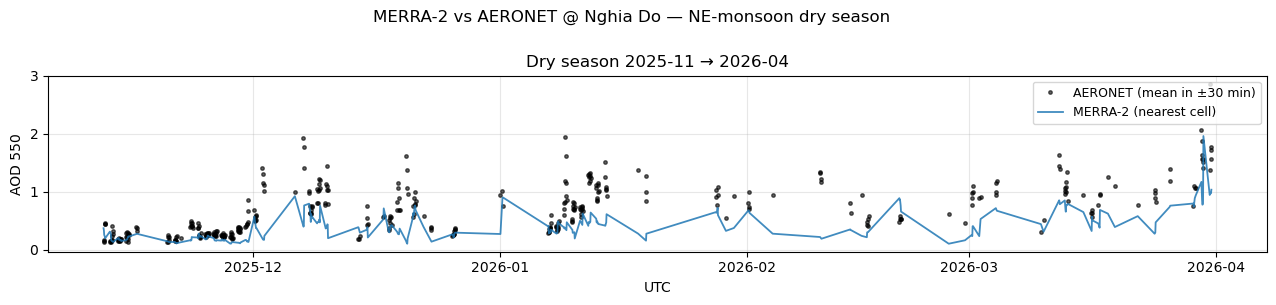

In [6]:
seasons = [
           ("2025-11-01", "2026-04-30")]

fig, axes = plt.subplots(len(seasons), 1, figsize=(13, 3.0 * len(seasons)),
                         sharey=True)
if len(seasons) == 1:
    axes = [axes]

for ax, (s, e) in zip(axes, seasons):
    sub = pairs[(pairs.time_utc >= s) & (pairs.time_utc < e)]
    if sub.empty:
        ax.set_title(f"{s[:7]} — {e[:7]}  (no data)")
        continue
    ax.plot(sub.time_utc, sub.aeronet_aod, "o", ms=2.5, color="black",
            alpha=0.6, label="AERONET (mean in ±30 min)")
    ax.plot(sub.time_utc, sub.model_aod, "-", color="tab:blue", lw=1.3,
            alpha=0.85, label="MERRA-2 (nearest cell)")
    ax.set_ylabel("AOD 550")
    ax.set_title(f"Dry season {s[:7]} → {e[:7]}")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=9)
axes[-1].set_xlabel("UTC")
fig.suptitle("MERRA-2 vs AERONET @ Nghia Do — NE-monsoon dry season", y=1.00)
fig.tight_layout()


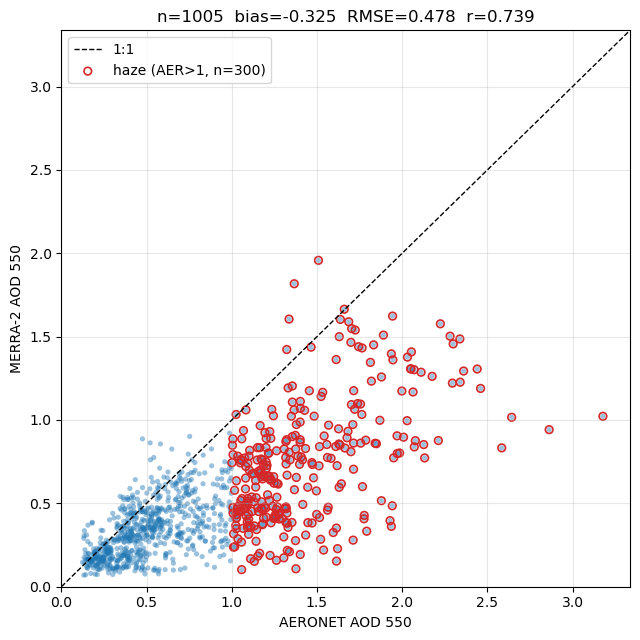

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(pairs.aeronet_aod, pairs.model_aod, s=14, alpha=0.45, edgecolor="none")
m = max(pairs.aeronet_aod.max(), pairs.model_aod.max()) * 1.05
ax.plot([0, m], [0, m], "k--", lw=1, label="1:1")
haze = pairs[pairs.aeronet_aod > 1.0]
ax.scatter(haze.aeronet_aod, haze.model_aod, s=30, facecolor="none",
           edgecolor="tab:red", lw=1.2, label=f"haze (AER>1, n={len(haze)})")
ax.set_xlim(0, m); ax.set_ylim(0, m)
ax.set_xlabel("AERONET AOD 550"); ax.set_ylabel("MERRA-2 AOD 550")
s = summarise(pairs)
ax.set_title(f"n={int(s['n'])}  bias={s['bias (MERRA2-AER)']:+.3f}  "
             f"RMSE={s['RMSE']:.3f}  r={s['r']:.3f}")
ax.grid(alpha=0.3); ax.legend(loc="upper left")
fig.tight_layout()


# Held-out AERONET validation — Stage-A-consistent rule

Everything above uses the notebook's own ad-hoc window (±30 min *did* match,
but Nov–Mar and Nghia Do only) — good for the "does MERRA-2 track haze?"
narrative but **not directly comparable** to Stage A's per-sensor table in
`AOD_map/stage_a/validate_persensor_aeronet.ipynb`.

This section rebuilds the MERRA-2-vs-AERONET comparison using the **exact**
collocation rule Stage A uses for held-out validation, so raw MERRA-2
becomes the second **native-reanalysis floor** against which Stage A's
soft-cal + TC-fusion lift can be read unambiguously.

Rule imported verbatim from [`AOD_map/stage_a/config.py`](../AOD_map/stage_a/config.py):

| ingredient | value | notes |
|---|---|---|
| window | `TEST_START` → `TEST_END` (2025-01-01 → 2026-04-30) | Stage A's §8 hold-out (memory: MERRA-2 anchor uses training window only, so hold-out is untouched) |
| sites | `AERONET_SITES` = `{NGHIA_DO (north), Bac_Lieu (south)}` | the two Stage A held-outs |
| seasons | `DRY_MONTHS` = Oct–Apr, `WET_MONTHS` = May–Sep | not the notebook's Nov–Mar |
| time collocation | ±`LEO_WINDOW_MIN` = ±30 min bucket around each MERRA-2 HH:30 timestamp | exactly the model's own averaging interval → clean pairing |
| spatial collocation | nearest MERRA-2 cell to station | 0.5°×0.625° — no 1×1→3×3→5×5 fallback (that's for 0.05° sat grids) |
| metrics | `compute_metrics` from `stage_a/validate.py` + OLS slope/intercept | same N, R, R², RMSE, MBE, %EE panel as §3 of `validate_persensor_aeronet.ipynb` |

**Note on MERRA-2's dual role.** MERRA-2 is Stage A's *training* anchor for
the linear soft calibration ([[project_stage_a_v3_6_schema]]), so its
own hold-out RMSE is meaningful in two ways: as a Stage B prior candidate
(currently not used per [[feedback_stage_b_no_merra2]]), and as a sanity
check that the training anchor isn't itself catastrophically wrong on the
haze regime it's supposed to pull sensors toward.


In [8]:
import sys
from pathlib import Path

# Pull the exact constants + metric function Stage A uses, so this notebook
# can't drift from `validate_persensor_aeronet.ipynb`.
sys.path.insert(0, str(Path("/home/work1/projects/Air_Quality/AOD_map/stage_a")))
from config import (
    AERONET_SITES, TEST_START, TEST_END,
    DRY_MONTHS, WET_MONTHS, LEO_WINDOW_MIN,
)
from validate import compute_metrics
from scipy import stats

DRY_M = sorted(DRY_MONTHS)   # Oct–Apr
WET_M = sorted(WET_MONTHS)   # May–Sep

AERONET_DIR = Path("/home/slow_data/Air_Quality/AERONET/process/aod_550/10")

def season_of(month: int) -> str:
    return "dry" if month in DRY_MONTHS else ("wet" if month in WET_MONTHS else "other")

# 1. AERONET × MERRA-2 pairs at both held-out stations, over the Stage A test window.
pairs_all = []
for site, meta in AERONET_SITES.items():
    aer = load_aeronet(AERONET_DIR / f"{site}.csv")
    aer = aer[(aer.time_utc >= str(TEST_START)) & (aer.time_utc <= str(TEST_END))]

    m2s = load_merra2_at_point(MERRA2_ROOT, meta["lat"], meta["lon"],
                                str(TEST_START), str(TEST_END))
    m2s = m2s[(m2s.time_utc >= str(TEST_START)) & (m2s.time_utc <= str(TEST_END))]

    p = pair_observations(aer, m2s, tolerance_minutes=LEO_WINDOW_MIN)
    p["site"]   = site
    p["season"] = p["time_utc"].dt.month.map(season_of)
    pairs_all.append(p)
    print(f"  {site:10s}: {len(p):4d} paired obs  "
          f"(AERONET {len(aer):,} / MERRA-2 {len(m2s):,}, ±{LEO_WINDOW_MIN} min)")

pairs_m2 = pd.concat(pairs_all, ignore_index=True)
print(f"\nTotal held-out pairs: {len(pairs_m2):,}")
pairs_m2.head()


Loading 485 MERRA-2 daily files…
Nearest MERRA-2 cell: (21.000, 105.625) vs station (21.048, 105.800)
  NGHIA_DO  :  717 paired obs  (AERONET 3,539 / MERRA-2 11,616, ±30 min)
Loading 485 MERRA-2 daily files…
Nearest MERRA-2 cell: (9.500, 105.625) vs station (9.280, 105.730)
  Bac_Lieu  :  755 paired obs  (AERONET 2,959 / MERRA-2 11,616, ±30 min)

Total held-out pairs: 1,472


,time_utc,aeronet_aod,model_aod,n_aeronet,site,season
0,2025-01-04 04:30:00,1.496488,0.574961,3,NGHIA_DO,dry
1,2025-01-06 03:30:00,1.104896,0.818182,9,NGHIA_DO,dry
2,2025-01-06 04:30:00,1.101336,0.783404,6,NGHIA_DO,dry
3,2025-01-06 05:30:00,1.149568,0.760151,5,NGHIA_DO,dry
4,2025-01-11 07:30:00,0.467472,0.337055,2,NGHIA_DO,dry


In [9]:
# --- OLS + per-stratum metric wrappers, verbatim from
#     `validate_persensor_aeronet.ipynb` §2–§3 so the numbers are directly
#     comparable to Stage A's per-sensor table. AERONET on x-axis, model on y.
def ols_regression(x: np.ndarray, y: np.ndarray) -> tuple[float, float]:
    res = stats.linregress(x, y)
    return float(res.slope), float(res.intercept)


def metrics_with_ols(sub: pd.DataFrame, label: str) -> dict:
    """compute_metrics + OLS slope/intercept on one stratum.

    `sub` must have columns `model_aod` (MERRA-2) and `aeronet_aod`.
    """
    sat = sub["model_aod"].to_numpy(dtype=np.float64)
    aer = sub["aeronet_aod"].to_numpy(dtype=np.float64)
    m   = compute_metrics(sat, aer, label=label)
    mask = np.isfinite(sat) & np.isfinite(aer)
    if mask.sum() >= 10:
        slope, intercept = ols_regression(aer[mask], sat[mask])
    else:
        slope, intercept = (np.nan, np.nan)
    m["slope"]     = slope
    m["intercept"] = intercept
    m["MBE"]       = m.pop("Bias")
    return m


In [10]:
def stratified_reanalysis(pairs: pd.DataFrame, sensor: str = "merra2") -> pd.DataFrame:
    """One row per (site, season) — same layout as persensor §3.

    Mirrors `stratified_persensor` in `validate_persensor_aeronet.ipynb`:
    for a fixed `sensor` label, emit rows for every (site, season) cell
    plus the site=ALL / season=ALL aggregate rows so a reader can see the
    marginal and the drilldown side by side.

    Rows with fewer than 10 pairs are still emitted (compute_metrics returns
    NaN R/R²/slope for them) — that N=… count is itself informative for a
    reanalysis floor: the wet season at Bac_Lieu is often the sparsest cell.

    TODO(you) — implement in ~8 lines. Design choices to make:

      (a) INCLUDE aggregate rows (site='ALL', season='ALL') so the panel
          matches persensor §3 line-for-line? Or emit only the four
          (site × season) cells, keeping the table tight for the floor
          write-up? persensor includes them — recommended for consistency.

      (b) Season buckets: use `DRY_MONTHS` / `WET_MONTHS` from stage_a
          config (already imported above). Rows with season='other' should
          not appear — the season column is already filled by `season_of`
          which only ever returns 'dry' or 'wet' inside the test window.

      (c) Iteration order: sort by (site, season) at the end so `Bac_Lieu`
          precedes `NGHIA_DO` and `dry` precedes `wet` alphabetically —
          matches persensor's row order.

    Pseudocode:
        sites_iter   = list(AERONET_SITES.keys()) + ['ALL']
        seasons_iter = ['dry', 'wet', 'ALL']
        rows = []
        for site in sites_iter:
            sub_site = pairs if site == 'ALL' else pairs[pairs.site == site]
            if sub_site.empty: continue
            for season in seasons_iter:
                sub = sub_site if season == 'ALL' else sub_site[sub_site.season == season]
                if sub.empty: continue
                m = metrics_with_ols(sub, label=f'{sensor} | {site} | {season}')
                m.update({'sensor': sensor, 'site': site, 'season': season})
                rows.append(m)
        return pd.DataFrame(rows)
    """
    sites_iter   = list(AERONET_SITES.keys()) + ['ALL']
    seasons_iter = ['dry', 'wet', 'ALL']
    rows = []
    for site in sites_iter:
        sub_site = pairs if site == 'ALL' else pairs[pairs.site == site]
        if sub_site.empty: continue
        for season in seasons_iter:
            sub = sub_site if season == 'ALL' else sub_site[sub_site.season == season]
            if sub.empty: continue
            m = metrics_with_ols(sub, label=f'{sensor} | {site} | {season}')
            m.update({'sensor': sensor, 'site': site, 'season': season})
            rows.append(m)
    return pd.DataFrame(rows)


panel_m2 = stratified_reanalysis(pairs_m2, sensor="merra2")
cols = ['sensor', 'site', 'season', 'N', 'R', 'R2', 'RMSE',
        'MBE', 'pct_EE', 'slope', 'intercept']
panel_m2 = panel_m2[cols].sort_values(['sensor', 'site', 'season']).reset_index(drop=True)
with pd.option_context('display.max_rows', None):
    print(panel_m2.round(3).to_string(index=False))


sensor     site season    N     R     R2  RMSE    MBE  pct_EE  slope  intercept
merra2      ALL    ALL 1472 0.800  0.402 0.434 -0.211  45.584  0.392      0.106
merra2      ALL    dry 1088 0.794  0.370 0.488 -0.251  41.268  0.389      0.123
merra2      ALL    wet  384 0.457 -0.006 0.218 -0.098  57.812  0.161      0.124
merra2 Bac_Lieu    ALL  755 0.700  0.375 0.134 -0.052  60.397  0.595      0.052
merra2 Bac_Lieu    dry  536 0.685  0.279 0.154 -0.070  52.799  0.605      0.047
merra2 Bac_Lieu    wet  219 0.514 -0.010 0.060 -0.006  78.995  0.528      0.066
merra2 NGHIA_DO    ALL  717 0.775  0.206 0.606 -0.380  29.986  0.377      0.120
merra2 NGHIA_DO    dry  552 0.758  0.147 0.668 -0.427  30.072  0.362      0.158
merra2 NGHIA_DO    wet  165 0.384 -0.578 0.325 -0.220  29.697  0.128      0.140


## How to read this against Stage A

Once the panel above runs, the `(sensor='merra2', site, season)` rows plug
directly into `validate_persensor_aeronet.ipynb` §3 as an **extra sensor**:

* MERRA-2 is Stage A's **soft-cal anchor** (§7.4.1) — the linear
  `MERRA2 = α · sat + β` fit is what pulls every raw sensor toward
  MERRA-2's climate. If raw MERRA-2 held-out RMSE is *worse* than the
  merged product in some stratum, the anchor is teaching sensors to be
  wrong there — a red flag for the [[project_himawari_north_dry_exclusion]]
  class of failure modes.
* Read raw-MERRA-2 alongside raw-CAMS: **if MERRA-2 out-performs CAMS at
  Bac_Lieu but under-performs at Nghia Do**, that's a spatial-anchor
  mis-alignment worth flagging in the write-up — and a hint at why
  [[feedback_stage_b_no_merra2]] keeps MERRA-2 out of Stage B despite
  its Stage A role.
* Together, `panel_cams` + `panel_m2` + `panel` (persensor) form the
  three-tier comparison the advisor asked for:
  **reanalysis floor → per-sensor raw → merged product**.

Save the panel to CSV if the §8 write-up will splice it into the persensor
LaTeX table:

```python
panel_m2.round(4).to_csv("figures/reanalysis_floor_merra2.csv", index=False)
```
